In [35]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


%matplotlib inline

In [2]:
train = pd.read_csv("train.csv")
econ = pd.read_csv("economic_indicators.csv")

In [3]:
train.columns = train.columns.str.lower().str.replace(" ", "_")

train_categorical = ["id", "country_id", "loan_type", "new_versus_repeat"]
train_dates = ["disbursement_date", "due_date"] # yyyy-mm-dd
train_numerical = ["customer_id", "tbl_loan_id", "lender_id", "total_amount", "total_amount_to_repay", "duration",
                   "amount_funded_by_lender", "lender_portion_funded", "lender_portion_to_be_repaid"]

#deal with categorical
for cat in train_categorical:
    train[cat] = train[cat].str.lower().str.replace(" ", "_")

# deal with dates

#deal with numerical


In [4]:
# We want "kenya"

# econ[econ['country'] == "kenya"]

In [5]:
econ.columns = econ.columns.str.lower().str.replace(" ", "_")

econ_categorical = ["country", "indicator"]

# deal with categorical
for cat in econ_categorical:
    econ[cat] = econ[cat].str.lower().str.replace(" ", "_")

In [9]:
for date in train_dates:
    train[date] = pd.to_datetime(train[date])

In [63]:
# train.isnull().sum() # No null entries
# train.duplicated().sum() # exact duplicates = 0

# Handling Outliers
train["duration_log"] = np.log1p(train["duration"])
train["total_amount_log"] = np.log1p(train['total_amount'])

In [29]:
train.total_amount.describe().apply(lambda x: f"{x:,.2f}")

count        68,654.00
mean         14,592.70
std         133,668.37
min               5.00
25%           2,289.00
50%           5,248.00
75%          11,388.00
max      20,000,000.00
Name: total_amount, dtype: str

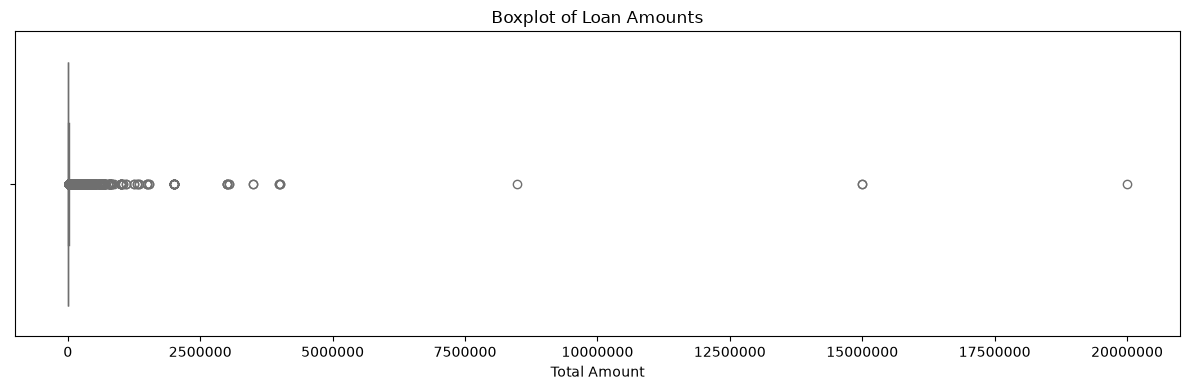

In [38]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=train["total_amount"], color="skyblue")

plt.title("Boxplot of Loan Amounts")
plt.xlabel("Total Amount")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

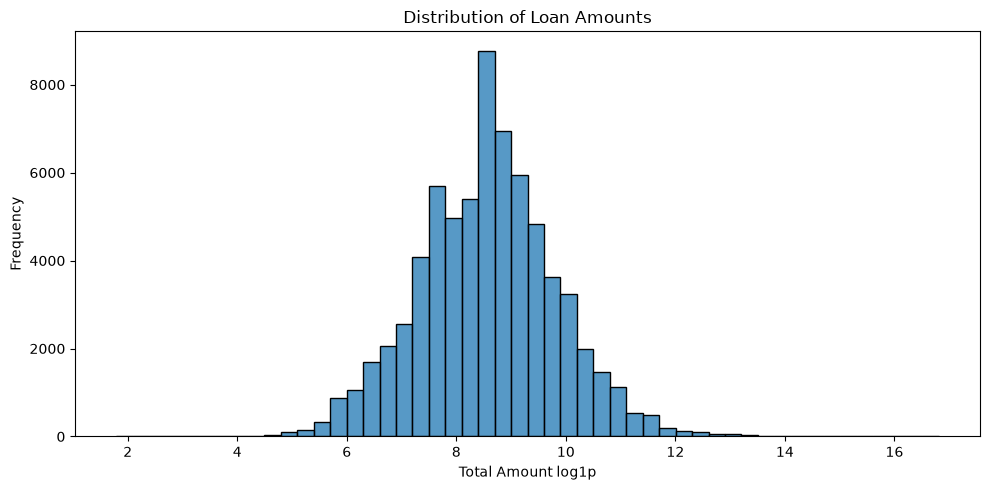

In [62]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="total_amount_log",
    bins=50
)

plt.title("Distribution of Loan Amounts")
plt.xlabel("Total Amount log1p")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [45]:
train.duration.describe()

count    68654.000000
mean         8.503569
std         13.426630
min          1.000000
25%          7.000000
50%          7.000000
75%          7.000000
max       1096.000000
Name: duration, dtype: float64

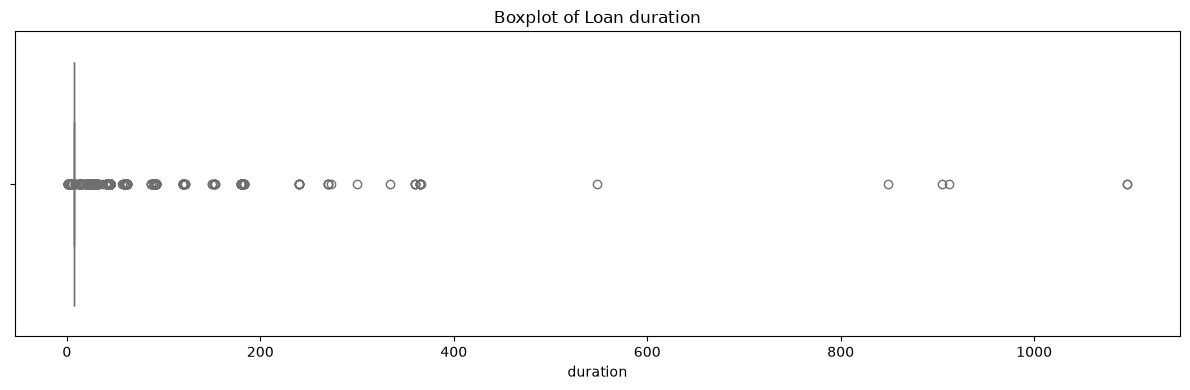

In [46]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=train["duration"], color="skyblue")

plt.title("Boxplot of Loan duration")
plt.xlabel("duration")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

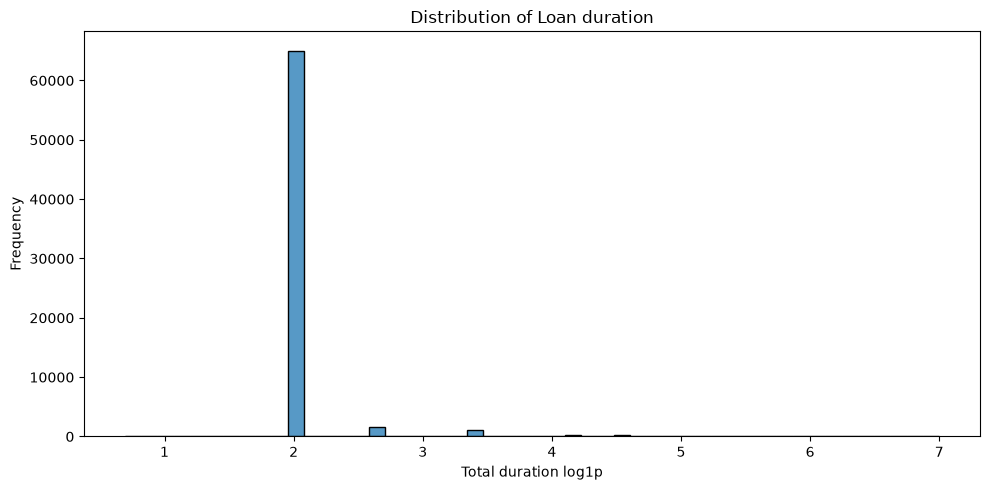

In [61]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="duration_log",
    bins=50
)

plt.title("Distribution of Loan duration")
plt.xlabel("Total duration log1p")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()